In [1]:
import pandas as pd
# Install spacy
## -q is for "quiet". It removes logs
!pip install spacy -q
# Import spacy, if you don't have it --> !pip install spacy
import spacy
spacy.__version__
# Download model
!python -m spacy download en_core_web_sm -q
# Import english stop words
from spacy.lang.en.stop_words import STOP_WORDS

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [2]:
data = pd.read_csv('data.csv')

In [3]:
import en_core_web_sm
nlp = en_core_web_sm.load() 
docs = list(nlp.pipe(data['description'].astype(str)))
for doc in docs:

# Print tokens
    print("Tokens: {}".format([token.text for token in doc]))
    print("------------")

    # Print Lemmatized tokens
    print("Lemma: {}".format([token.lemma_ for token in doc]))
    print("------------")

    # Print Indices of each tokens
    print("Indices: {}".format([token.i for token in doc]))
    print("------------")

    # Print whether tokens are alpha numeric
    print("Alpha Numeric: {}".format([token.is_alpha for token in doc]))
    print("------------")

    # Print whether tokens are numbers
    print("Numbers: {}".format([token.like_num for token in doc]))

Tokens: ['Active', 'classic', 'boxers', '-', 'There', "'s", 'a', 'reason', 'why', 'our', 'boxers', 'are', 'a', 'cult', 'favorite', '-', 'they', 'keep', 'their', 'cool', ',', 'especially', 'in', 'sticky', 'situations', '.', 'The', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'up', 'minimal', 'space', 'in', 'a', 'travel', 'pack', '.', 'An', 'exposed', ',', 'brushed', 'waistband', 'offers', 'next', '-', 'to', '-', 'skin', 'softness', ',', 'five', '-', 'panel', 'construction', 'with', 'a', 'traditional', 'boxer', 'back', 'for', 'a', 'classic', 'fit', ',', 'and', 'a', 'functional', 'fly', '.', 'Made', 'of', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'with', 'moisture', '-', 'wicking', 'performance', '.', 'Inseam', '(', 'size', 'M', ')', 'is', '4', '1/2', '"', '.', 'Recyclable', 'through', 'the', 'Common', 'Threads', 'Recycling', 'Program.<br><br><b', '>', 'Details:</b><ul', '>', '<', 'li>"Silky', 'Capilene', '1', 'fabric', 'is', 'ultralight', ',', 'breathabl

In [4]:
# Print stop words
print(STOP_WORDS)

{'such', '‘m', 'last', 'becomes', 'some', 'front', 'always', 'call', 'really', 'a', 'where', 'around', 'perhaps', 'this', 'until', 'is', 'anyone', 'me', 'its', 'when', 'i', 'somehow', 'unless', 'am', 'third', 'back', 'also', 'and', 'beside', 'eight', 'meanwhile', 'alone', 'quite', "'s", 'n‘t', 'very', 'most', 'seem', 'yourself', 'put', 'enough', 'hereupon', 'above', 'has', 'everyone', 'mostly', 'doing', 'therein', 'amount', 'down', 'an', 'part', 'other', 'might', 'my', 'several', 'too', 'using', 'whole', 'your', '’d', 'rather', 'from', 'across', 'everything', 'became', 'yet', 'which', 'do', 'itself', 'besides', 'his', 'being', '‘ll', 'less', 'there', 'she', 'fifty', 'does', 'already', 'along', 'then', 'us', 'towards', 'ten', 'it', 'no', 'latterly', 'myself', 'only', 'now', '’s', 'keep', 'per', '‘re', 'name', 'wherever', 'sixty', 'though', '’ll', 'used', 'can', 'must', 'anything', 'full', 'mine', 'moreover', 'so', 'fifteen', 'since', 'whither', 'many', '‘s', 'thereafter', 'one', 'forty'

In [5]:
# Install wordcloud if necessary
!pip install wordcloud -q

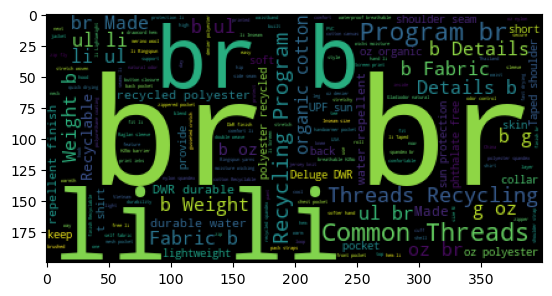

In [6]:
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud

# Instanciate WordCloud
wd = wordcloud.WordCloud()
text = " ".join(data['description'].astype(str))
cloud = wd.generate(text)

# Show word cloud with matplotlib
plt.imshow(cloud)

# Remove trailing logs
plt.show()

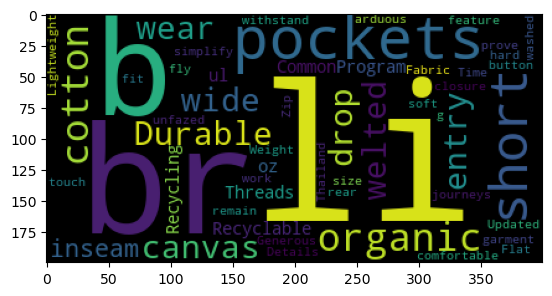

In [8]:
# Instanciate WordCloud with no stop words
wd = wordcloud.WordCloud(stopwords=STOP_WORDS)

# Generate word cloud
cloud = wd.generate(doc.text)

# Show with matplotlib
plt.imshow(cloud)

# Remove trailing log
plt.show()

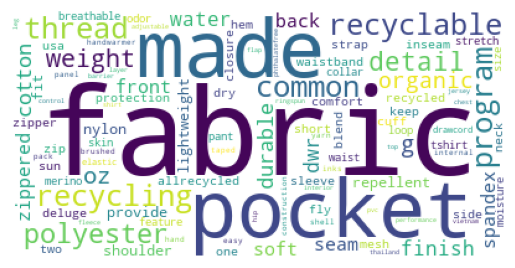

In [7]:
import re
# Import matplotlib and wordcloud
import matplotlib.pyplot as plt
import wordcloud

text = " ".join(data['description'].astype(str))
text = re.sub(r"<[^>]+>", " ", text)
text = re.sub(r"[!\"#$%&()*+,-./:;<=>?@[\\\]^_`{|}~]+", "", text).lower() # lowercase

# Create lemmatization
lemma = [token.lemma_ for token in doc if token.lemma_ not in STOP_WORDS]

cloud = wordcloud.WordCloud(collocations=False, background_color="white", colormap="viridis").generate(text) # élimine les paires de mots

# Show word cloud with matplotlib
plt.imshow(cloud)
plt.axis("off")

# Remove trailing logs
plt.show()

La taille d’un mot dépend de sa fréquence dans le texte : plus il est gros, plus il apparaît souvent. La position, l’orientation et la couleur sont aléatoires et n’ont aucune signification. dwr signifie Durable Water Repellent. g pourrait mesurer le poids. 

Prochaines étapes 
puis data mining avec tf idf
retirer le bruit

In [9]:
# import displacy
from spacy import displacy

# render displacy
displacy.render(doc, style='dep', jupyter=True,options={'distance': 70})